In [1]:
#!pip install -q inference-gpu[yolo-world]==0.11.1 #0.9.13
#!pip install -q supervision==0.19.0rc3
#!pip install opencv-python
#!pip install plotly

In [2]:
import os

from traitlets import import_item
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
import cv2
import supervision as sv
import numpy as np
import json
from datetime import datetime

from tqdm import tqdm
from inference.models import YOLOWorld

import sys

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import load_images_and_combine
from utils import detect_yolo_world, yolo_plot, nms_yolo, remove_big_box_yolo, grounded_segmentation

[06/02/24 16:31:10] WARNING  Your inference package version 0.11.1 is out of date! Please upgrade to ]8;id=139135;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py\__init__.py]8;;\:]8;id=387066;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py#35\35]8;;\
                             version 0.11.2 of inference for the latest features and bug fixes by                  
                             running `pip install --upgrade inference`.                                            

2024-06-02 16:31:14.197000: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-06-02 16:31:15.299620: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


## Model and data

In [3]:
# yolo_world/s, yolo_world/m, and yolo_world/l
yolo_model_id = "yolo_world/l"
segmenter_id = "facebook/sam-vit-base"

yolo_model = YOLOWorld(model_id=yolo_model_id)

confidence=0.001
labels= ["colorful cutted circle", "colorful circle", "coloful sticker", "colorful patch", "part of colorful sticker", "part of colorful patch", "part of colorful circle", "colorful semicircle", "colorful ellipsoid", "coloful cutted ellipsoid"]


Creating inference sessions


/usr/local/lib/python3.10/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:65: UserWarning: Specified provider 'OpenVINOExecutionProvider' is not in available provider names.Available providers: 'TensorrtExecutionProvider, CUDAExecutionProvider, CPUExecutionProvider'
  warnings.warn(
2024-06-02 16:31:21.637824044 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:640 CreateExecutionProviderInstance] Failed to create CUDAExecutionProvider. Please reference https://onnxruntime.ai/docs/execution-providers/CUDA-ExecutionProvider.html#requirements to ensure all dependencies are met.


CLIP model loaded in 1.26 seconds


2024-06-02 16:31:22.269179637 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:640 CreateExecutionProviderInstance] Failed to create CUDAExecutionProvider. Please reference https://onnxruntime.ai/docs/execution-providers/CUDA-ExecutionProvider.html#requirements to ensure all dependencies are met.


In [4]:
# load images
num_imgs = 100
images = load_images_and_combine(dir_path="/workspace/home/data/ISIC2019/raw", num_imgs=num_imgs)

# output file
data_dict = {}
data_dict['yolo_model_id'] = yolo_model_id
data_dict['num_imgs'] = num_imgs
data_dict['confidence_threshold'] = confidence
data_dict['custom_vocabulary'] = labels

  0%|          | 0/100 [00:00<?, ?it/s]/workspace/home01/utils/detection_and_segmentation_utils.py:667: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:261.)
  scores = torch.tensor([scores]).squeeze()


Detections(xyxy=array([[     110.29,      1401.6,      1742.6,      2011.7],
       [     1529.5,      731.76,      2022.1,      1251.1]]), mask=None, confidence=array([    0.13797,   0.0010073]), class_id=array([8, 9]), tracker_id=None, data={'class_name': array(['colorful ellipsoid', 'coloful cutted ellipsoid'], dtype='<U24')})


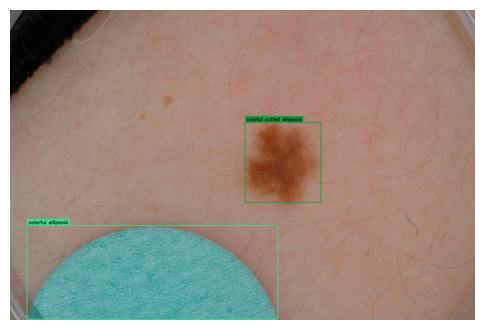

  1%|          | 1/100 [00:15<25:36, 15.52s/it]

Detections(xyxy=array([[     505.72,      1474.7,      2095.3,      2013.9]]), mask=None, confidence=array([    0.30157]), class_id=array([7]), tracker_id=None, data={'class_name': array(['colorful semicircle'], dtype='<U24')})


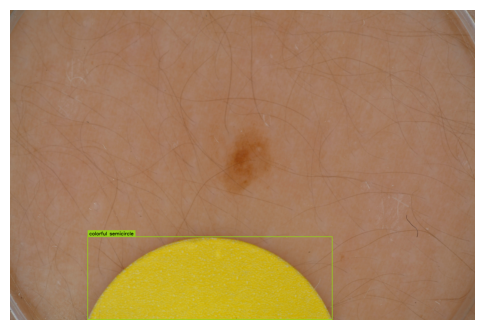

  2%|▏         | 2/100 [00:29<23:31, 14.40s/it]

Detections(xyxy=array([[     521.68,      1555.8,      2035.1,      2011.1]]), mask=None, confidence=array([   0.037147]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


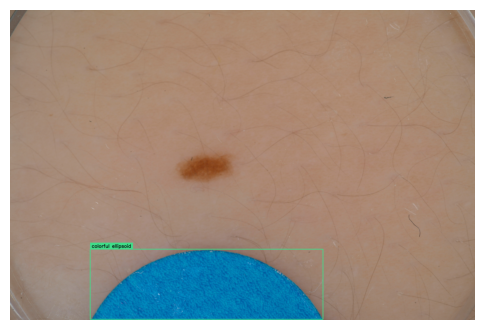

  3%|▎         | 3/100 [00:42<22:35, 13.97s/it]

Detections(xyxy=array([[     805.96,        1284,      2499.2,      2009.7]]), mask=None, confidence=array([    0.51986]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


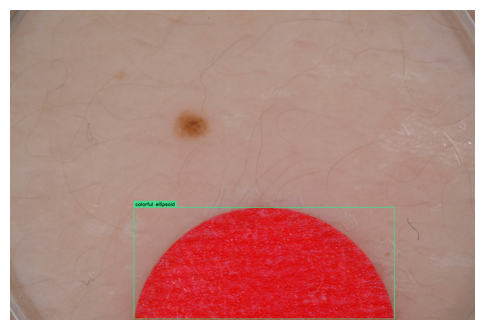

  4%|▍         | 4/100 [00:57<23:04, 14.42s/it]

Detections(xyxy=array([[        640,      1582.7,      2147.7,      2013.5]]), mask=None, confidence=array([    0.30042]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


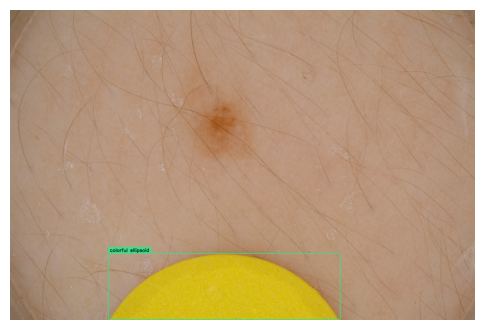

  5%|▌         | 5/100 [01:11<22:36, 14.28s/it]

Detections(xyxy=array([[          0,      1227.4,      645.49,      2011.5]]), mask=None, confidence=array([   0.013304]), class_id=array([7]), tracker_id=None, data={'class_name': array(['colorful semicircle'], dtype='<U24')})


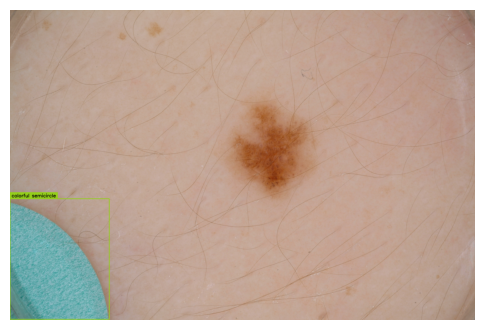

  6%|▌         | 6/100 [01:24<21:37, 13.80s/it]

Detections(xyxy=array([[     774.24,      1716.2,      2070.3,      2012.2]]), mask=None, confidence=array([   0.023798]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U22')})


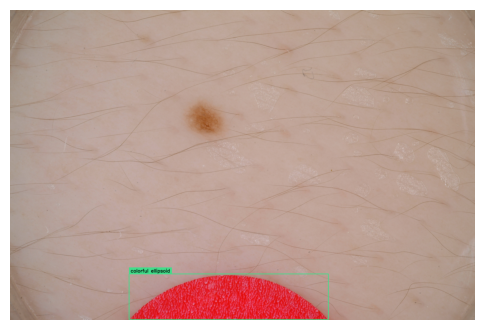

  7%|▋         | 7/100 [01:37<20:42, 13.36s/it]

Detections(xyxy=array([[     725.88,        1643,      2145.4,      2011.8]]), mask=None, confidence=array([   0.025706]), class_id=array([1]), tracker_id=None, data={'class_name': array(['colorful circle'], dtype='<U24')})


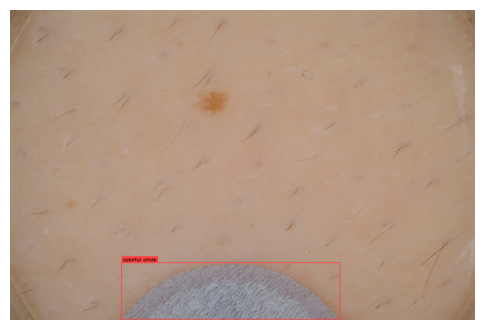

  8%|▊         | 8/100 [01:47<19:08, 12.48s/it]

Detections(xyxy=array([[     663.19,      1542.3,      2189.9,      2011.5]]), mask=None, confidence=array([    0.01084]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


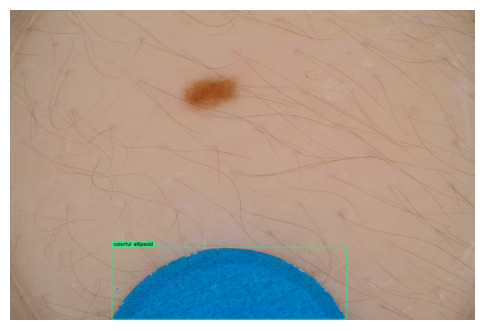

  9%|▉         | 9/100 [01:57<17:44, 11.70s/it]

Detections(xyxy=array([[          0,      1232.6,        1491,      2015.2]]), mask=None, confidence=array([      0.627]), class_id=array([7]), tracker_id=None, data={'class_name': array(['colorful semicircle'], dtype='<U24')})


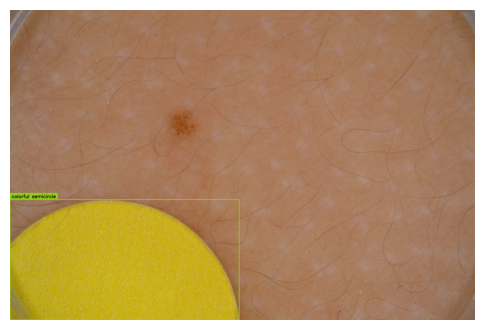

 10%|█         | 10/100 [02:07<16:46, 11.19s/it]

Detections(xyxy=array([[       1029,      1174.2,        2740,        2014]]), mask=None, confidence=array([    0.36946]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


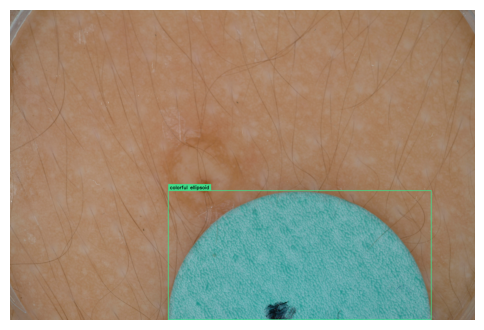

 11%|█         | 11/100 [02:17<15:52, 10.70s/it]

Detections(xyxy=array([], shape=(0, 4), dtype=float32), mask=None, confidence=array([], dtype=float32), class_id=array([], dtype=int64), tracker_id=None, data={})


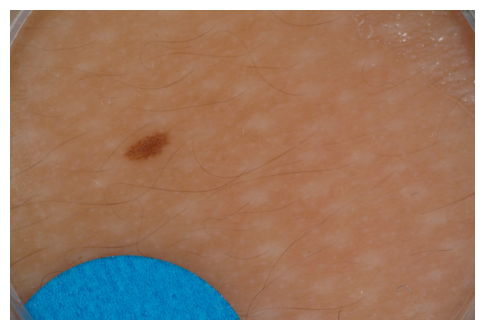

 12%|█▏        | 12/100 [02:27<15:26, 10.53s/it]

Detections(xyxy=array([[     1222.9,      918.18,      2932.8,      2012.3]]), mask=None, confidence=array([     0.7004]), class_id=array([7]), tracker_id=None, data={'class_name': array(['colorful semicircle'], dtype='<U24')})


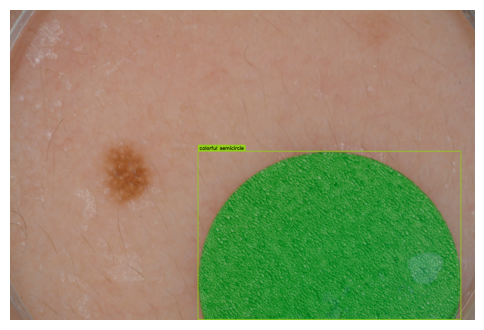

 13%|█▎        | 13/100 [02:38<15:30, 10.70s/it]

Detections(xyxy=array([[     1154.9,        1644,      2568.3,      2014.3]]), mask=None, confidence=array([  0.0044971]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


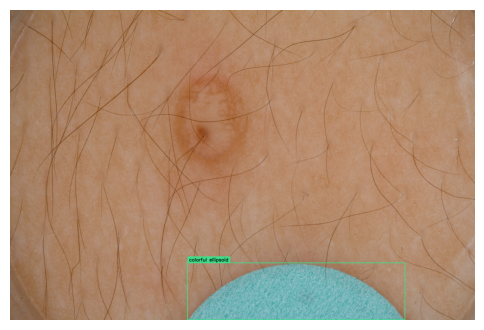

 14%|█▍        | 14/100 [02:48<15:11, 10.59s/it]

Detections(xyxy=array([[     1247.2,      1776.8,        2422,      2013.6]]), mask=None, confidence=array([  0.0017213]), class_id=array([7]), tracker_id=None, data={'class_name': array(['colorful semicircle'], dtype='<U19')})


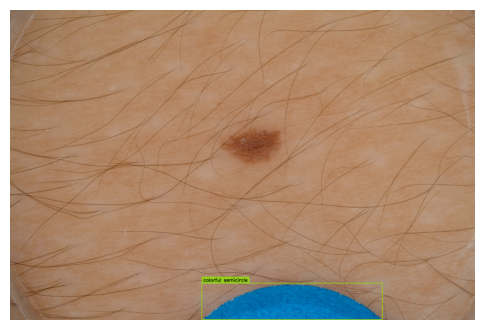

 15%|█▌        | 15/100 [02:58<14:26, 10.19s/it]

Detections(xyxy=array([[     170.62,      1486.6,        1724,      2010.4]]), mask=None, confidence=array([    0.12304]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


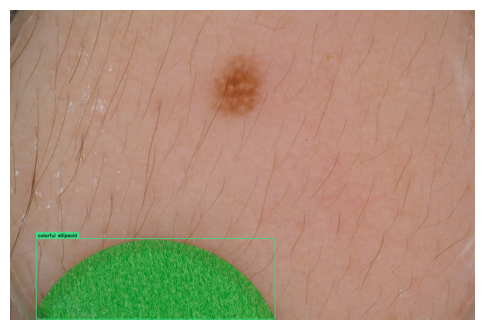

 16%|█▌        | 16/100 [03:07<13:55,  9.94s/it]

Detections(xyxy=array([[     1444.7,      935.37,      3023.2,        2015]]), mask=None, confidence=array([    0.52457]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


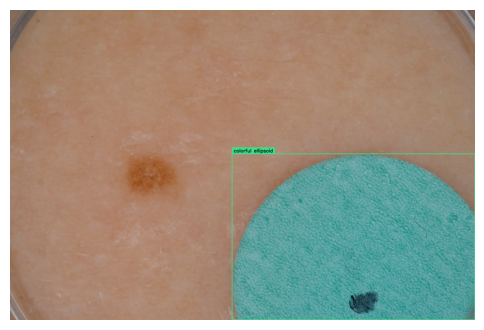

 17%|█▋        | 17/100 [03:18<14:11, 10.26s/it]

Detections(xyxy=array([[     1294.4,      1244.4,      2995.5,        2016]]), mask=None, confidence=array([   0.053783]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


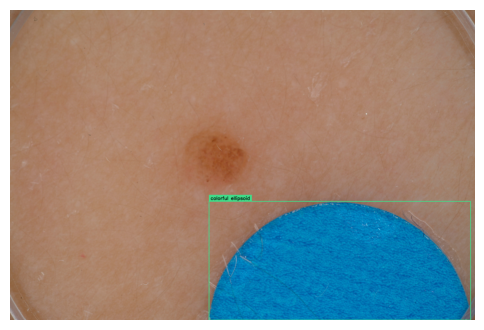

 18%|█▊        | 18/100 [03:27<13:32,  9.91s/it]

Detections(xyxy=array([[     444.64,      1296.1,      2125.4,      2010.1]]), mask=None, confidence=array([    0.42928]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


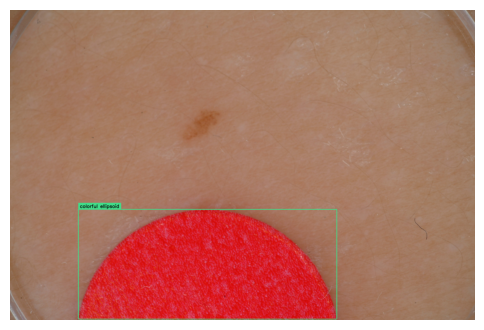

 19%|█▉        | 19/100 [03:36<13:05,  9.70s/it]

Detections(xyxy=array([[     1368.2,      1345.6,      3006.8,      2010.9]]), mask=None, confidence=array([    0.61953]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


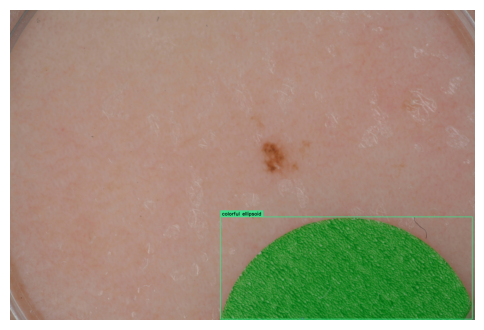

 20%|██        | 20/100 [03:45<12:41,  9.52s/it]

Detections(xyxy=array([[     1464.7,      1567.2,      2947.3,      2012.2]]), mask=None, confidence=array([   0.031784]), class_id=array([8]), tracker_id=None, data={'class_name': array(['colorful ellipsoid'], dtype='<U24')})


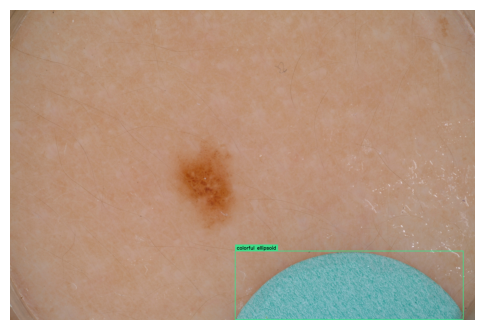

 21%|██        | 21/100 [04:08<15:34, 11.83s/it]


RuntimeError: scores should be a 1d tensor, got 0D

In [6]:
for i, image_dict in enumerate(tqdm(images[:num_imgs])):
    #image = image_dict['image']
    meta = image_dict['meta']

    # image
    image_path = meta['file_path']

    image = cv2.imread(image_path)

    detections = detect_yolo_world(image, yolo_model, confidence, labels)
    detections = remove_big_box_yolo(detections, (image.shape[0], image.shape[1]), area_threshold=0.9)
    detections = nms_yolo(detections, 0.8)
    print(detections)
    print("Number of detections: ", len(detections.xyxy))

    yolo_plot(image, detections)


    #image_array, detections = grounded_segmentation(
    #    image=image_path,
    #    labels=labels,
    #    threshold=confidence,
    #    polygon_refinement=True,
    #    detector_id=detector_id,
    #    segmenter_id=segmenter_id
    #)
    
    #yolo_plot(image_array, detections)
    

# 